In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

2024-07-10 12:36:57.960369: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-07-10 12:36:58.013349: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-07-10 12:36:58.013386: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-07-10 12:36:58.014852: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-07-10 12:36:58.023117: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-07-10 12:36:58.024017: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [3]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=4)
print(f'current stimulus is {D.movname}')
mov_ind = D.mov_ind

current stimulus is opticflow


In [4]:
V_width = 1
V_E_buffer = 11
E_width = 1
setup = (V_width,V_E_buffer,E_width)
N_trials = 20
N_neurons = 40

dns = ds.DataNatScenes
def emptyfunc(_):
    pass
# trial_keys = ["control", "time", "cell", "both"]
# shuffle_methods = [emptyfunc, dns.shuffle_trial_per_time, dns.shuffle_trial_per_cell, dns.shuffle_trial]

trial_keys = ["control", "time", "cell"]
shuffle_methods = [emptyfunc, dns.shuffle_trial_per_time, dns.shuffle_trial_per_cell]

opt_params = {"track_quantities": False, "quiet": True, "iterations": 1}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}

critic_params = {
    "hidden_dim": 32,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}

experiment_configuration_variables = {'N_neurons', 'trial_keys', 'mi_measurement_params', 'N_trials', 'opt_params', 'V_width', 'V_E_buffer', 'E_width', 'critic_params'}

## Run test

In [5]:
experiment_dims = (N_trials,)
mi_averages_test = {}
mi_stdevs_test = {}
mi_averages_train = {}
mi_stdevs_train = {}
for key in trial_keys:
    mi_averages_test[key] = np.zeros(experiment_dims)
    mi_stdevs_test[key] = np.zeros(experiment_dims)
    mi_averages_train[key] = np.zeros(experiment_dims)
    mi_stdevs_train[key] = np.zeros(experiment_dims)
    
for n in tqdm(range(N_trials)):
    for k, key in enumerate(trial_keys):   
        D.reset()
        D.trim(20)
        D.subset_features(range(N_neurons))
        _ = shuffle_methods[k](D)
        V, E = D.create_V_and_E_datasets(*setup)
        train_points, test_points = tools.generate_train_test_indices(V.P, 0.5)
        
        critic_function = mds.SeparableCritic(**critic_params)
        
        # training set
        V.subset_points(train_points)
        E.subset_points(train_points)
        als.train_NCE(
            X=V.X,
            Y=E.X,
            critic_function=critic_function,
            **opt_params
        )

        # measure InfoNCE for train
        mi_train = als.MI_NCE(
            X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )

        # measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(test_points)
        E.subset_points(test_points)
        mi_test = als.MI_NCE(
            X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )

        mi_averages_test[key][n] = mi_test["mi"]
        mi_stdevs_test[key][n] = mi_test["mi_stdev"]
        mi_averages_train[key][n] = mi_train["mi"]
        mi_stdevs_train[key][n] = mi_train["mi_stdev"]
    

  0%|          | 0/20 [00:00<?, ?it/s]2024-07-10 12:37:02.829415: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-07-10 12:37:02.830452: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2256] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
100%|██████████| 20/20 [06:39<00:00, 19.99s/it]


## Save

In [6]:
# select variables
critic_type = type(critic_function)
critic_config = critic_function.get_config()
save_vars = {
    "mi_averages_train",
    "mi_averages_test",
    "mi_stdevs_train",
    "mi_stdevs_test",
    "critic_type",
    "critic_config"
}.union(experiment_configuration_variables)
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [7]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, '', strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')

stim = D.movname
save_directory = os.path.join(cur_directory, 'saved', stim)
# full_file_path = os.path.join(save_directory, f'trial shuffle comparisons {setup} N={N_neurons} high-iter.dat')
full_file_path = os.path.join(save_directory, f'trial shuffle comparisons {setup} N={N_neurons}.dat')
# full_file_path = os.path.join(save_directory, 'test.dat')
# print(f"will save to {save_directory}")
print(f"will save to {full_file_path}")

will save to /home/adam/Documents/projects/retina-past-future-ib/analyses/noise correlations/saved/opticflow/trial shuffle comparisons (1, 11, 1) N=40.dat


In [8]:
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)

## Reload and plot

In [9]:
stim = 'opticflow'
setup = (1,11,1)
N_neurons = 40
V_width, V_E_buffer, E_width = setup

# load_path = f'./saved/{stim}/trial shuffle comparisons {setup} N={N_neurons} high-iter.dat'
load_path = f'./saved/{stim}/trial shuffle comparisons {setup} N={N_neurons}.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)


In [10]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    full_stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, full_stdevs

In [11]:
average_test = {}
stdevs_test = {}
average_train = {}
stdevs_train = {}

for k, key in enumerate(data.trial_keys):
    average_test[key], stdevs_test[key] = process_trials(data.mi_averages_test[key], data.mi_stdevs_test[key])
    average_train[key], stdevs_train[key] = process_trials(data.mi_averages_train[key], data.mi_stdevs_train[key])

Text(0.5, 1.0, 'Trial shuffling with $N=40$ neurons,\n $(V,B,E)=(1, 11, 1)$, under opticflow stim')

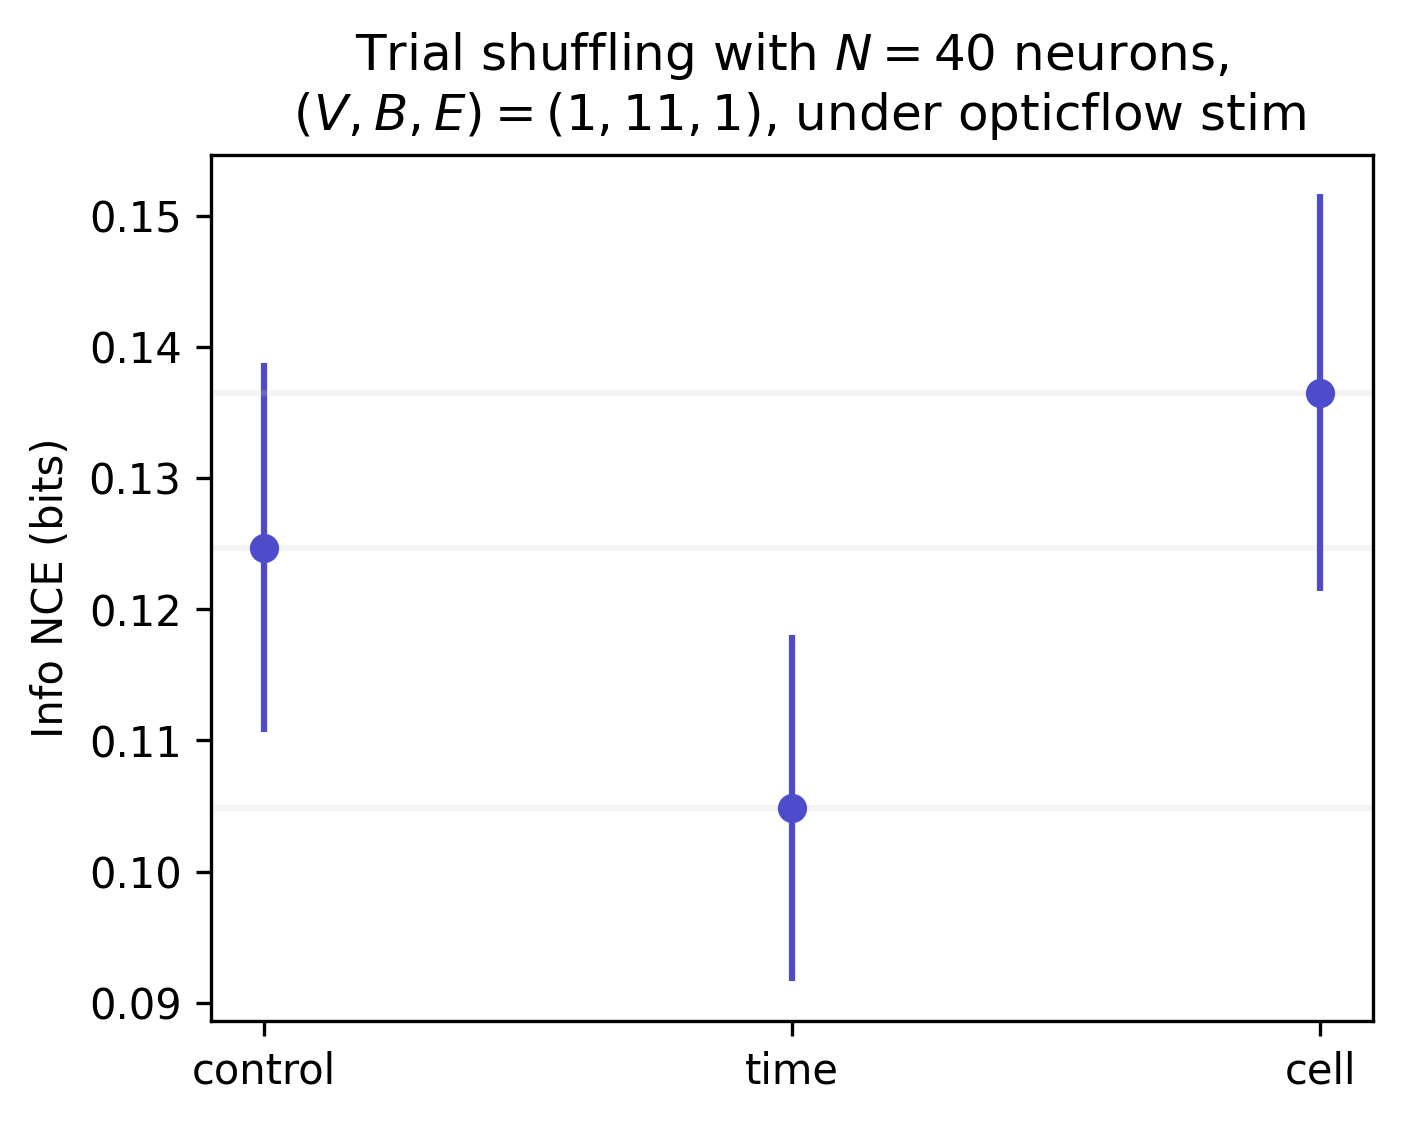

In [12]:
c1 = 0.3
c2 = 0.8
alp = 0.2
fig, ax = plt.subplots(dpi=300, figsize=[5,5 * 3 / 4])

show_train = False

N_keys = len(data.trial_keys)
# x = np.arange(4)
x = np.arange(N_keys)
w = 0.1 if show_train else 0

for k, key in enumerate(data.trial_keys):
    if show_train:
        y = average_train[key] / np.log(2)
        yerr = stdevs_train[key] / np.log(2)
        ax.errorbar(x[k] - w, y, yerr, marker='o', color=(c1,c2,c1))

    y = average_test[key] / np.log(2)
    yerr = stdevs_test[key] / np.log(2)
    ax.errorbar(x[k] + w, y, yerr, marker='o', color=(c1,c1,c2))
    ax.axhline(y, color=(c2,c2,c2,alp))


ax.set_xticks(x)
ax.set_xticklabels(data.trial_keys)
ax.set_ylabel("Info NCE (bits)")
ax.set_title(f"Trial shuffling with $N={N_neurons}$ neurons,\n $(V,B,E)={setup}$, under {stim} stim")

In [13]:
dI = {}
for k in data.trial_keys:
    dI[k] = average_test["control"] - average_test[k]

In [9]:
dI["time"] + dI["cell"] - dI["both"]

0.19743108582585622

In [42]:
C = N_neurons**2 / D.N_trials

In [43]:
C

12.047058823529412